# Options Pricing on an Egg

Long before financial derivatives dominated the **Chicago Mercantile Exchange (CME)**, the exchange was founded in 1898 as the **Chicago Butter and Egg Board**, where futures and options were literally traded on eggs.

There is also a deep mathematical link between **boiling an egg** and **pricing financial options**: both are governed by the **parabolic heat diffusion equation**. This notebook has three parts:

1. **The Black-Scholes $\leftrightarrow$ Heat Equation Duality.** The Black-Scholes PDE is transformed into the 1D heat equation and a European call is priced with `scikit-fem` P1 finite elements. This part is an exact numerical identity that can be checked against a closed form.
2. **Egg Doneness Derivative Pricing (Corridor Digital Option).** A *"Soft-Boil Warranty"* pays 10 USD if the temperature of the coldest point of the yolk surface at the pull time lies in the soft-boil window $[63^\circ\text{C}, 70^\circ\text{C}]$, under kitchen-to-kitchen uncertainty in starting temperature, bath temperature and egg size.
3. **American Option / Optimal Stopping (*"When to Pull the Egg"*).** A cook reads a noisy in-egg thermometer and decides when to pull the egg. The value of that thermometer over a blind timer is computed with **Longstaff-Schwartz Least-Squares Monte Carlo (LSM)**.

**What is and is not modeled.** The egg is not a traded asset. The "prices" in parts 2 and 3 are expected culinary payoffs under an assumed distribution of kitchens, not no-arbitrage prices, and nothing in them is calibrated to a market or to cooking data. The temperature paths come from the finite-element egg of the earlier notebooks (one FEM run, rescaled to other kitchens by similarity scaling, with the approximation checked against direct FEM runs). The $63^\circ\text{C}$ to $70^\circ\text{C}$ window is a modeling choice motivated by protein set points, defined in `egg_fem.doneness`.

## Setup

In [1]:
%matplotlib inline
from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from egg_fem import (
    HeatSolver,
    KitchenUncertainty,
    ThermalResponse,
    T_BOILING,
    T_ROOM,
    black_scholes_call,
    check_similarity_against_fem,
    create_egg_mesh,
    egg_white_properties,
    egg_yolk_properties,
    mesh_volume,
    price_egg_corridor_option,
    solve_american_egg_option,
    solve_black_scholes_heat_fem,
)
from egg_fem.doneness import crossing_time, doneness_times

KELVIN = 273.15

# Plot style: three categorical hues (blue, orange, aqua), neutral grays, light grid.
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.frameon": False,
    "legend.fontsize": 9,
})


def fmt_pm(value, se):
    # "value +- se" with one significant digit of the standard error (at least 2 decimals).
    decimals = max(2, int(-np.floor(np.log10(se)))) if se > 0 else 2
    return f"{value:.{decimals}f} +- {se:.{decimals}f}"


def zero_clean(x, digits=2):
    # Round and drop negative zero so that "-0.00" is not printed.
    return round(float(x), digits) + 0.0


def print_table(header, rows):
    # Print a plain-text table: first column left-aligned, the rest right-aligned.
    table = [[str(x) for x in header]] + [[str(x) for x in row] for row in rows]
    widths = [max(len(row[j]) for row in table) for j in range(len(header))]
    for i, row in enumerate(table):
        cells = [row[0].ljust(widths[0])] + [row[j].rjust(widths[j]) for j in range(1, len(row))]
        print("  ".join(cells))
        if i == 0:
            print("  ".join("-" * w for w in widths))

## 1. The Black-Scholes $\leftrightarrow$ Heat Equation Duality

A standard European option $V(S, t)$ on an underlying asset $S$ with volatility $\sigma$ and risk-free rate $r$ satisfies the **Black-Scholes PDE**:

$$\frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + r S \frac{\partial V}{\partial S} - r V = 0, \qquad V(S, T) = \max(S - K, 0)$$

Applying the classic log-price and time-reversal change of variables:

$$x = \ln\left(\frac{S}{K}\right), \qquad \tau = \frac{1}{2}\sigma^2 (T - t), \qquad k = \frac{2r}{\sigma^2}, \qquad \alpha = -\frac{1}{2}(k - 1), \qquad \beta = -\frac{1}{4}(k + 1)^2$$

and factoring out $V(S, t) = K e^{\alpha x + \beta \tau} u(x, \tau)$ reduces the Black-Scholes PDE to the **1D dimensionless heat equation**:

$$\frac{\partial u}{\partial \tau} = \frac{\partial^2 u}{\partial x^2}$$

Just as heat diffuses inward from the hot shell toward the egg center over physical time $t$, option value diffuses outward from the kink at strike $S = K$ ($x = 0$) backward from maturity ($\tau = 0$) to the present ($\tau = \frac{1}{2}\sigma^2 T$). Below we solve this heat equation using `scikit-fem` P1 finite elements and Backward Euler time-stepping, then compare with the closed-form Black-Scholes price.

The error is measured **at the mesh nodes** whose price $S$ lies in $[50, 150]$ (the nodes do not fall exactly on 50 and 150, so the actual node range is printed).

European call: K = 100, T = 1 yr, r = 0.05, sigma = 0.25
Mesh: 401 nodes on x = ln(S/K) in [-2.5, 2.5], 400 Backward Euler steps
Error evaluated at the 88 nodes with S in [50, 150] (actual node range 50.28 to 149.18)
At-the-money (S = 100) call price:
  1D heat FEM (scikit-fem): 12.3325 USD
  Exact Black-Scholes:      12.3360 USD
Max nodal error on that range: 0.00354 USD (at S = 101.26)


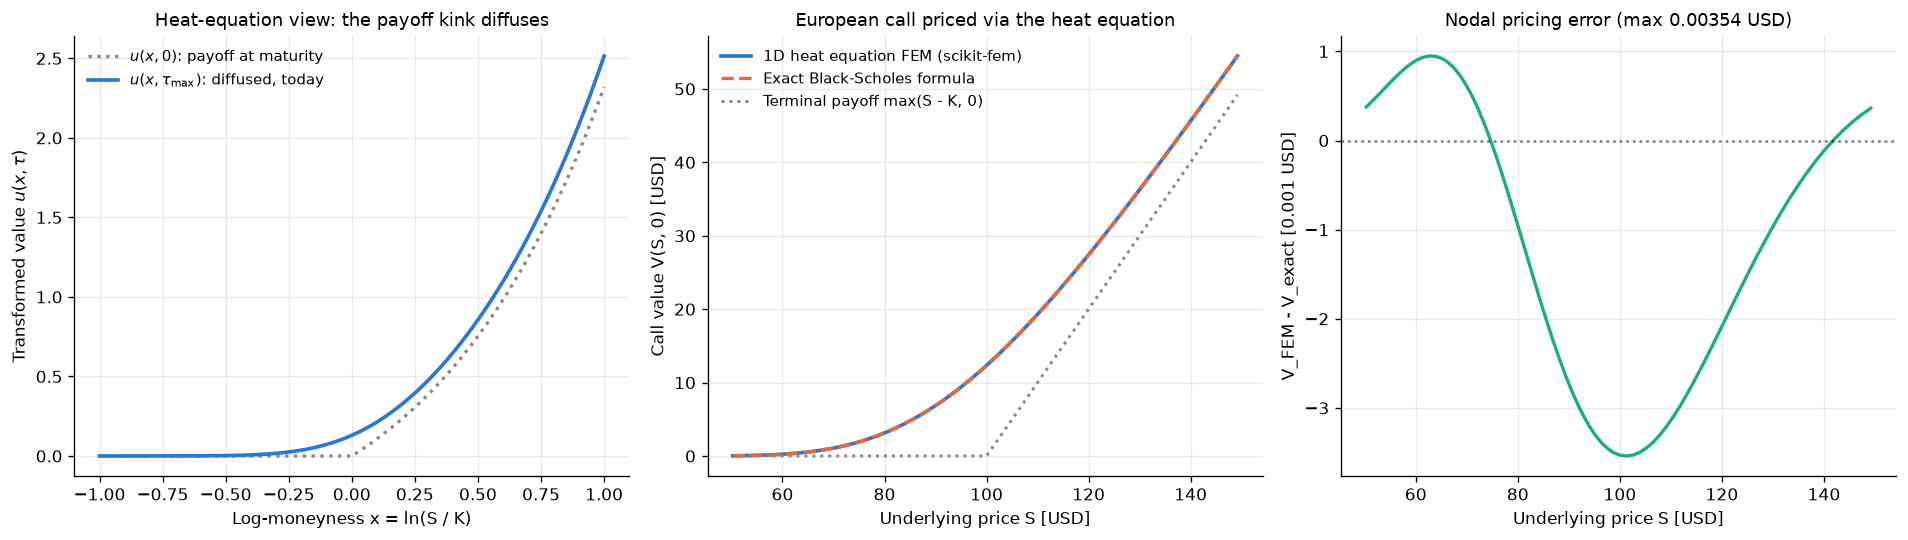

In [2]:
K = 100.0
T_mat = 1.0
r_rate = 0.05
sigma = 0.25
N_NODES, N_STEPS = 401, 400

bs_res = solve_black_scholes_heat_fem(
    K=K, T=T_mat, r=r_rate, sigma=sigma, n_nodes=N_NODES, n_steps=N_STEPS
)

# Error is evaluated at the mesh nodes whose price S lies in [50, 150].
S_LO, S_HI = 50.0, 150.0
mask = (bs_res["S"] >= S_LO) & (bs_res["S"] <= S_HI)
S_grid = bs_res["S"][mask]
V_fem = bs_res["V_fem"][mask]
V_exact = bs_res["V_exact"][mask]
payoff = np.maximum(S_grid - K, 0.0)

nodal_err = np.abs(V_fem - V_exact)
max_err = float(nodal_err.max())
S_at_max_err = float(S_grid[nodal_err.argmax()])
v_atm_fem = float(np.interp(K, S_grid, V_fem))
v_atm_exact = float(black_scholes_call(K, K, T_mat, r_rate, sigma))

print(f"European call: K = {K:.0f}, T = {T_mat:.0f} yr, r = {r_rate:.2f}, sigma = {sigma:.2f}")
print(f"Mesh: {N_NODES} nodes on x = ln(S/K) in [-2.5, 2.5], {N_STEPS} Backward Euler steps")
print(f"Error evaluated at the {mask.sum()} nodes with S in [{S_LO:.0f}, {S_HI:.0f}] "
      f"(actual node range {S_grid.min():.2f} to {S_grid.max():.2f})")
print(f"At-the-money (S = {K:.0f}) call price:")
print(f"  1D heat FEM (scikit-fem): {v_atm_fem:.4f} USD")
print(f"  Exact Black-Scholes:      {v_atm_exact:.4f} USD")
print(f"Max nodal error on that range: {max_err:.3g} USD (at S = {S_at_max_err:.2f})")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ax = axes[0]
x_view = np.abs(bs_res["x"]) <= 1.0
ax.plot(bs_res["x"][x_view], bs_res["u_init"][x_view], color=GRAY, ls=":", lw=2.0,
        label=r"$u(x, 0)$: payoff at maturity")
ax.plot(bs_res["x"][x_view], bs_res["u_final"][x_view], color=BLUE, lw=2.2,
        label=r"$u(x, \tau_{\max})$: diffused, today")
ax.set_xlabel("Log-moneyness x = ln(S / K)")
ax.set_ylabel(r"Transformed value $u(x, \tau)$")
ax.set_title("Heat-equation view: the payoff kink diffuses")
ax.legend(loc="upper left")

ax = axes[1]
ax.plot(S_grid, V_fem, color=BLUE, lw=2.2, label="1D heat equation FEM (scikit-fem)")
ax.plot(S_grid, V_exact, color=ORANGE, ls="--", lw=2.0, label="Exact Black-Scholes formula")
ax.plot(S_grid, payoff, color=GRAY, ls=":", lw=1.8, label="Terminal payoff max(S - K, 0)")
ax.set_xlabel("Underlying price S [USD]")
ax.set_ylabel("Call value V(S, 0) [USD]")
ax.set_title("European call priced via the heat equation")
ax.legend(loc="upper left")

ax = axes[2]
ax.plot(S_grid, (V_fem - V_exact) * 1000.0, color=AQUA, lw=2.0)
ax.axhline(0, color="k", ls=":", alpha=0.5)
ax.set_xlabel("Underlying price S [USD]")
ax.set_ylabel("V_FEM - V_exact [0.001 USD]")
ax.set_title(f"Nodal pricing error (max {max_err:.3g} USD)")

plt.tight_layout()
fig.savefig("../figures/bs_heat_duality.png", dpi=150, bbox_inches="tight")
plt.show()

**Time-step convergence.** Backward Euler is only **first order** in the time step, while the P1 elements are second order in the node spacing. On the 401-node mesh the error stops shrinking once the spatial error takes over (the ratio to the previous row falls below 2 and tends to 1). On a 3201-node mesh the spatial error is small over the same range of steps, so halving the step halves the error: the ratio is close to 2, which is first order in time. The error is the maximum nodal error on the same $S$ range as above.

In [3]:
def max_nodal_error(**kwargs):
    res = solve_black_scholes_heat_fem(K=K, T=T_mat, r=r_rate, sigma=sigma, **kwargs)
    m = (res["S"] >= S_LO) & (res["S"] <= S_HI)
    return float(np.max(np.abs(res["V_fem"][m] - res["V_exact"][m])))


rows = []
for n_nodes, step_list in ((401, (50, 100, 200, 400, 800, 1600, 3200)),
                           (3201, (25, 50, 100, 200, 400, 800))):
    previous = None
    for n_steps in step_list:
        err = max_nodal_error(n_nodes=n_nodes, n_steps=n_steps)
        ratio = "" if previous is None else f"{previous / err:.2f}"
        rows.append((n_nodes, n_steps, f"{err:.3g}", ratio))
        previous = err
print_table(["nodes", "steps", "max nodal error [USD]", "ratio to previous row"], rows)


nodes  steps  max nodal error [USD]  ratio to previous row
-----  -----  ---------------------  ---------------------
401       50                 0.0201                       
401      100                 0.0106                   1.89
401      200                0.00591                   1.80
401      400                0.00354                   1.67
401      800                0.00236                   1.50
401     1600                0.00179                   1.32
401     3200                 0.0016                   1.12
3201      25                 0.0379                       
3201      50                  0.019                   2.00
3201     100                0.00951                   2.00
3201     200                0.00477                   2.00
3201     400                0.00239                   1.99
3201     800                0.00121                   1.98


**The transform is unsafe at small volatility.** The substitution multiplies the solution by $e^{\alpha x + \beta \tau}$, and for small $\sigma$ the constant $k = 2r/\sigma^2$ is large, so $u$ spans an enormous dynamic range and double-precision round-off (and eventually overflow) destroys the price. The solver therefore raises `ValueError` when the scale factor exceeds $e^{40}$ instead of returning a wrong or non-finite number. The guard only protects against round-off and overflow: accuracy also degrades earlier, before the guard triggers, as the table shows. A narrower $x$-domain lowers the scale factor, and the closed form `black_scholes_call` is always available.

In [4]:
rows, messages = [], {}
for sig in (0.25, 0.15, 0.10, 0.06, 0.05, 0.02):
    k_const = 2.0 * r_rate / sig**2
    try:
        res = solve_black_scholes_heat_fem(K=K, T=T_mat, r=r_rate, sigma=sig, n_nodes=N_NODES, n_steps=N_STEPS)
        m = (res["S"] >= S_LO) & (res["S"] <= S_HI)
        outcome = f"max nodal error {np.max(np.abs(res['V_fem'][m] - res['V_exact'][m])):.3g} USD"
    except ValueError as exc:
        outcome = "ValueError"
        messages[sig] = str(exc)
    rows.append((f"{sig:.2f}", f"{k_const:.3g}", outcome))
print_table(["sigma", "k = 2r/sigma^2", "result (K = 100, domain x in [-2.5, 2.5])"], rows)

print("\nMessage for sigma = 0.05:")
print(messages[0.05])

# A narrower domain makes sigma = 0.05 solvable.  The S range it covers is smaller.
narrow = solve_black_scholes_heat_fem(
    K=K, T=T_mat, r=r_rate, sigma=0.05, x_min=-0.5, x_max=0.5, n_nodes=N_NODES, n_steps=N_STEPS
)
m = (narrow["S"] >= 60.0) & (narrow["S"] <= S_HI)
print(f"\nsigma = 0.05 on x in [-0.5, 0.5]: max nodal error "
      f"{np.max(np.abs(narrow['V_fem'][m] - narrow['V_exact'][m])):.3g} USD "
      f"on S in [{narrow['S'][m].min():.1f}, {narrow['S'][m].max():.1f}]")

sigma  k = 2r/sigma^2  result (K = 100, domain x in [-2.5, 2.5])


-----  --------------  -----------------------------------------
0.25              1.6                max nodal error 0.00354 USD
0.15             4.44                max nodal error 0.00332 USD
0.10               10                max nodal error 0.00676 USD
0.06             27.8                 max nodal error 0.0647 USD
0.05               40                                 ValueError
0.02              250                                 ValueError

Message for sigma = 0.05:
k = 2r/sigma^2 = 40 is too large for the domain [-2.5, 2.5]: the log-space transform scales the solution by exp(51.78) (limit exp(40)), which overflows or destroys the accuracy.  Use a larger sigma, a narrower x-domain, or the closed-form black_scholes_call.

sigma = 0.05 on x in [-0.5, 0.5]: max nodal error 0.0153 USD on S in [60.7, 149.9]


## 2. The Thermal Underlying: One FEM Run, Rescaled to Other Kitchens

The corridor option and the stopping problem need the probe temperature of an egg in tens of thousands of different kitchens. Re-running the FEM for every Monte Carlo path would be far too slow, so the finance module uses **similarity scaling**:

1. Run the FEM **once** for the default egg (starting at $20^\circ\text{C}$, Dirichlet bath at $100^\circ\text{C}$) and store the dimensionless response of a probe,
$$\theta(t) = \frac{T_{\text{probe}}(t) - T_{\text{bath}}}{T_{\text{init}} - T_{\text{bath}}}.$$
2. For a kitchen with starting temperature $T_0$, bath temperature $T_b$ and linear size scale $s$ (every length multiplied by $s$), use
$$T(t; T_0, T_b, s) = T_b + (T_0 - T_b)\,\theta\!\left(t / s^2\right).$$

Size scaling follows from the heat equation (time scales like length squared) and does not involve the material properties, so it is exact up to discretization. Scaling the starting and bath temperatures is exact only for constant material properties; the egg's properties depend on temperature, so this part is an **approximation**. It is checked below against direct FEM runs of the perturbed kitchen.

**The probe.** The default probe is `white_min`: the coldest temperature anywhere in the egg white. For the default egg this point lies on the yolk surface, at the top of the yolk on the symmetry axis (checked below at the moments the probe reaches 63, 66.5 and 70 degrees), so the probe is the temperature of the coldest point of the yolk surface, not of the yolk surface as a whole (Section 3 shows how much of the yolk is hotter). When it reaches $63^\circ\text{C}$ the whole white has reached its set temperature and even the coolest point of the yolk surface is at $63^\circ\text{C}$, the soft-boiled criterion of `egg_fem.doneness`. It reaches $70^\circ\text{C}$, the yolk set temperature, at that one point long before the yolk center does. The yolk center is available as a second probe for comparison.

In [5]:
mesh = create_egg_mesh()                      # default egg: 55 x 42 mm, 15 mm yolk
materials = {"white": egg_white_properties, "yolk": egg_yolk_properties}
T0_REF, TB_REF = T_ROOM, T_BOILING            # 20 C egg in a 100 C Dirichlet bath

egg_volume_mL = mesh_volume(mesh) * 1e6
yolk_volume_mL = 4.0 / 3.0 * np.pi * 0.015**3 * 1e6
print(f"Default egg: 55 x 42 mm, volume {egg_volume_mL:.1f} mL, yolk radius 15 mm "
      f"({yolk_volume_mL:.1f} mL = {100 * yolk_volume_mL / egg_volume_mL:.0f}% of the egg)")
print(f"Reference kitchen: egg at {T0_REF - KELVIN:.1f} C, bath at {TB_REF - KELVIN:.1f} C, "
      "dt = 1 s, 1200 s simulated")

resp = ThermalResponse.from_fem(probe="white_min", mesh=mesh, materials=materials)
resp_center = ThermalResponse.from_fem(probe="center", mesh=mesh, materials=materials)
print(f"Two FEM runs: {resp!r} and {resp_center!r}")

# Direct run with the doneness module, for the soft / medium / hard definitions and a location check.
solver = HeatSolver(mesh, materials, T_init=T0_REF, T_boundary=TB_REF, dt=1.0)
solver.run(1200.0, progress=False)
done = doneness_times(solver)

targets = (63.0, 66.5, 70.0)
print("\nDefault kitchen (20 C egg, 100 C bath): time for the probe to reach a temperature [s]")
rows = [("white_min (coldest white point)",
         *[f"{resp.time_to_reach(T, T0_REF, TB_REF):.1f}" for T in targets]),
        ("yolk center",
         *[f"{resp_center.time_to_reach(T, T0_REF, TB_REF):.1f}" for T in targets])]
print_table(["probe", "63.0 C", "66.5 C", "70.0 C"], rows)

print("\nDoneness times from egg_fem.doneness on the same FEM run [s]:")
print(f"  soft   (coldest white point reaches 63 C):          {done['soft']:.1f}")
print(f"  medium (at least 50% of the yolk volume >= 70 C):   {done['medium']:.1f}")
print(f"  hard   (coldest yolk point reaches 70 C):           {done['hard']:.1f}")

# Where is the coldest white point? Check at the times the probe reaches 63, 66.5 and 70 C.
times_run = np.array(solver.times)
white_nodes = np.unique(mesh.t[:, mesh.subdomains["white"]])
print("\nLocation of the coldest white node (yolk center at z = -2 mm, yolk radius 15 mm):")
for T_target in targets:
    t_hit = resp.time_to_reach(T_target, T0_REF, TB_REF)
    i_hit = int(np.searchsorted(times_run, t_hit))
    T_field = np.asarray(solver.temperatures[i_hit])
    k_cold = white_nodes[int(np.argmin(T_field[white_nodes]))]
    r_cold, z_cold = mesh.p[:, k_cold]
    dist_mm = 1000.0 * float(np.hypot(r_cold, z_cold - (-0.002)))
    print(f"  t = {times_run[i_hit]:.0f} s ({T_target:.1f} C): r = {1000 * r_cold:.1f} mm, "
          f"z = {1000 * z_cold:.1f} mm, {dist_mm:.1f} mm from the yolk center")

Default egg: 55 x 42 mm, volume 50.6 mL, yolk radius 15 mm (14.1 mL = 28% of the egg)
Reference kitchen: egg at 20.0 C, bath at 100.0 C, dt = 1 s, 1200 s simulated


Two FEM runs: ThermalResponse(probe='white_min', t_end_s=1200, n_times=1201) and ThermalResponse(probe='center', t_end_s=1200, n_times=1201)



Default kitchen (20 C egg, 100 C bath): time for the probe to reach a temperature [s]
probe                            63.0 C  66.5 C  70.0 C
-------------------------------  ------  ------  ------
white_min (coldest white point)   343.3   373.1   406.7
yolk center                       615.4   654.7   697.6

Doneness times from egg_fem.doneness on the same FEM run [s]:
  soft   (coldest white point reaches 63 C):          343.3
  medium (at least 50% of the yolk volume >= 70 C):   438.8
  hard   (coldest yolk point reaches 70 C):           697.6

Location of the coldest white node (yolk center at z = -2 mm, yolk radius 15 mm):
  t = 344 s (63.0 C): r = 0.0 mm, z = 13.0 mm, 15.0 mm from the yolk center
  t = 374 s (66.5 C): r = 0.0 mm, z = 13.0 mm, 15.0 mm from the yolk center
  t = 407 s (70.0 C): r = 0.0 mm, z = 13.0 mm, 15.0 mm from the yolk center


**The old sphere surrogate.** Earlier versions of this notebook drove the Monte Carlo with a homogeneous sphere (`fourier_sphere_center_temp`, radius 22.8 mm, diffusivity $1.32 \times 10^{-7}\ \text{m}^2/\text{s}$) instead of the FEM. A sphere has no yolk, no egg shape and no temperature-dependent properties, so it cannot match the FEM center temperature. The same code now builds a response from that sphere with `ThermalResponse.from_sphere`, for comparison with the FEM yolk-center response.

In [6]:
sphere = ThermalResponse.from_sphere(R_eff=0.0228, alpha_diff=1.32e-7, t_end=1200.0, n_times=1201)

center_targets = (63.0, 65.0, 70.0)
fem_c = [resp_center.time_to_reach(T, T0_REF, TB_REF) for T in center_targets]
sph_c = [sphere.time_to_reach(T, T0_REF, TB_REF) for T in center_targets]
rows = [("FEM yolk center", *[f"{t:.1f}" for t in fem_c]),
        ("earlier sphere surrogate", *[f"{t:.1f}" for t in sph_c]),
        ("sphere minus FEM", *[f"{a - b:+.1f}" for a, b in zip(sph_c, fem_c)])]
print("Time for the yolk center to reach a temperature, default kitchen [s]")
print_table(["", "63.0 C", "65.0 C", "70.0 C"], rows)

Time for the yolk center to reach a temperature, default kitchen [s]
                          63.0 C  65.0 C  70.0 C
------------------------  ------  ------  ------
FEM yolk center            615.4   637.4   697.6
earlier sphere surrogate   579.1   602.1   665.3
sphere minus FEM           -36.3   -35.3   -32.3


**Similarity scaling versus direct FEM.** For each perturbed kitchen, `check_similarity_against_fem` runs the FEM directly on an egg with every length (and mesh size) multiplied by $s$ and the time step multiplied by $s^2$, and compares it with the rescaled reference response. The table lists the crossing times of the direct run, the difference *scaled minus direct*, and the largest temperature difference over the whole run. The temperature difference includes a tiny start-up artifact: the FEM start undershoots the initial temperature slightly and the response is clipped to start exactly at the initial temperature. The differences have one sign for a given type of kitchen (cold eggs and cool baths come out early, warm eggs late), so they shrink the spread between kitchens instead of averaging out; Section 5 measures what that does to the prices.

5 direct FEM runs

Probe: white_min.  Crossing times at 63.0 / 66.5 / 70.0 C
kitchen                       direct [s]  scaled - direct [s]  % at 66.5 C  max |dT| [C]
---------------------  -----------------  -------------------  -----------  ------------
cold egg: 8 C          388.4/418.8/453.0    -3.05/-3.08/-3.11        -0.74         0.603
cool bath: 98.5 C      350.7/382.0/417.5    -0.70/-0.79/-0.88        -0.21         0.083
larger egg: s = 1.03   364.2/395.8/431.4    +0.00/+0.00/+0.00        +0.00         0.032
8 C, 98.5 C, s = 1.03  421.0/454.9/493.3    -4.12/-4.25/-4.39        -0.93         0.661
32 C, 100 C, s = 0.97  274.9/302.6/333.5    +2.72/+2.75/+2.79        +0.91         0.434



Probe: yolk center, kitchen 8 C, 98.5 C, s = 1.03.  Crossing times at 63.0 / 70.0 C
  direct 727.7 / 817.3 s, scaled - direct -6.14 / -6.33 s, max |dT| 0.684 C


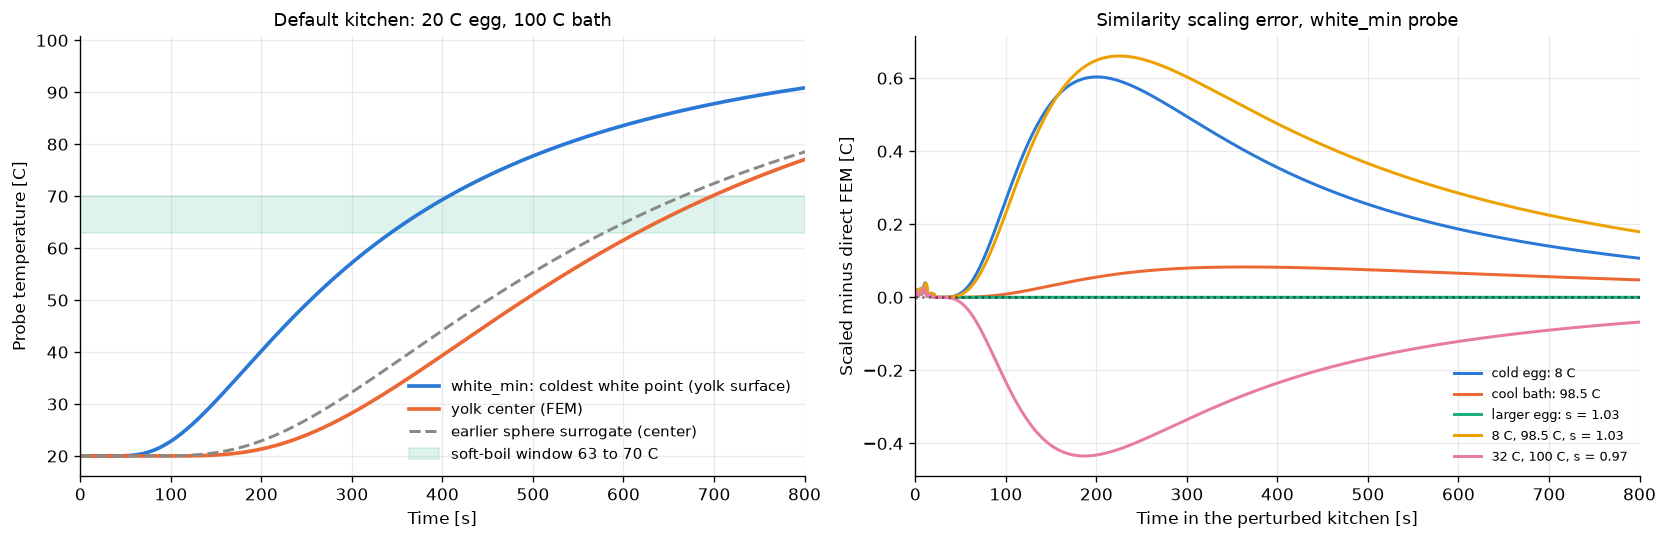

In [7]:
kitchens = [
    ("cold egg: 8 C", 8.0, 100.0, 1.00),
    ("cool bath: 98.5 C", 20.0, 98.5, 1.00),
    ("larger egg: s = 1.03", 20.0, 100.0, 1.03),
    ("8 C, 98.5 C, s = 1.03", 8.0, 98.5, 1.03),
    ("32 C, 100 C, s = 0.97", 32.0, 100.0, 0.97),
]

sim_checks = []
for name, T0_C, Tb_C, s in kitchens:
    chk = check_similarity_against_fem(resp, T0_C + KELVIN, Tb_C + KELVIN, s, thresholds_C=targets)
    sim_checks.append((name, chk))
print(f"{len(kitchens)} direct FEM runs\n")

rows = []
for name, chk in sim_checks:
    rows.append((
        name,
        "/".join(f"{t:.1f}" for t in chk["t_direct_s"]),
        "/".join(f"{zero_clean(d):+.2f}" for d in chk["t_diff_s"]),
        f"{zero_clean(100 * chk['t_diff_s'][1] / chk['t_direct_s'][1]):+.2f}",
        f"{chk['max_abs_diff_C']:.3f}",
    ))
print("Probe: white_min.  Crossing times at 63.0 / 66.5 / 70.0 C")
print_table(["kitchen", "direct [s]", "scaled - direct [s]", "% at 66.5 C", "max |dT| [C]"], rows)

# The same check for the yolk-center probe in the combined kitchen.
chk_c = check_similarity_against_fem(resp_center, 8.0 + KELVIN, 98.5 + KELVIN, 1.03, thresholds_C=(63.0, 70.0))
print("\nProbe: yolk center, kitchen 8 C, 98.5 C, s = 1.03.  Crossing times at 63.0 / 70.0 C")
print(f"  direct {chk_c['t_direct_s'][0]:.1f} / {chk_c['t_direct_s'][1]:.1f} s, "
      f"scaled - direct {chk_c['t_diff_s'][0]:+.2f} / {chk_c['t_diff_s'][1]:+.2f} s, "
      f"max |dT| {chk_c['max_abs_diff_C']:.3f} C")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

ax = axes[0]
t_plot = resp.times_s
ax.plot(t_plot, resp(t_plot, T0_REF, TB_REF) - KELVIN, color=BLUE, lw=2.2,
        label="white_min: coldest white point (yolk surface)")
ax.plot(t_plot, resp_center(t_plot, T0_REF, TB_REF) - KELVIN, color=ORANGE, lw=2.2,
        label="yolk center (FEM)")
ax.plot(t_plot, sphere(t_plot, T0_REF, TB_REF) - KELVIN, color=GRAY, ls="--", lw=1.8,
        label="earlier sphere surrogate (center)")
ax.axhspan(63.0, 70.0, color=AQUA, alpha=0.15, label="soft-boil window 63 to 70 C")
ax.set_xlim(0, 800)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Probe temperature [C]")
ax.set_title("Default kitchen: 20 C egg, 100 C bath")
ax.legend(loc="lower right")

ax = axes[1]
for (name, chk), color in zip(sim_checks, SERIES):
    ax.plot(chk["times_s"], chk["T_scaled_C"] - chk["T_direct_C"], color=color, lw=1.8, label=name)
ax.axhline(0, color="k", ls=":", alpha=0.5)
ax.set_xlim(0, 800)
ax.set_xlabel("Time in the perturbed kitchen [s]")
ax.set_ylabel("Scaled minus direct FEM [C]")
ax.set_title("Similarity scaling error, white_min probe")
ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

## 3. Egg Doneness Derivative Pricing: The "Soft-Boil Warranty" (Corridor Option)

In a real kitchen, boiling an egg is not deterministic. Three conditions vary from egg to egg, and the same model is used for the corridor option and for the stopping problem in Section 4:

- **Starting temperature** $T_0 \sim \mathcal{N}(20^\circ\text{C}, (3.5^\circ\text{C})^2)$: how long the egg sat on the counter.
- **Bath temperature** $T_b = 100^\circ\text{C} - |Z|$ with $Z \sim \mathcal{N}(0, (1.2^\circ\text{C})^2)$: water that is slightly below a full boil by a half-normal amount. It is never above $100^\circ\text{C}$ (sea-level boiling), and there is no probability mass piled up at exactly $100^\circ\text{C}$.
- **Linear size scale** $s \sim \mathcal{N}(1, 0.02^2)$: every length of the reference egg is multiplied by $s$. Mass scales like $s^3$, so this is a mass coefficient of variation of about 6%. This is a modeling choice: a uniform spread within one carton grade (US Large 56.7 to 63.8 g, EU M 53 to 63 g) would be a mass CV of 3.4% to 5.0%, a `size_cv` of about 1.1% to 1.7%, and a mix of grades would be much wider.

**Not in the model.** The position of the yolk inside the egg varies from egg to egg, and the soft level moves by roughly 25 s per mm of axial yolk displacement (Notebook 03), so the true spread of the probe at a given time is wider than modeled here. A refrigerator start at $8^\circ\text{C}$ is 3.4 standard deviations below the mean of the starting-temperature model, so fridge eggs are outside it.

A breakfast kitchen issues a **binary corridor digital option** (a *"Soft-Boil Warranty"*) that pays $N = 10$ USD if the probe temperature at the pull time $t_{\text{pull}}$ lies inside the soft-boil corridor $[K_{\text{low}}, K_{\text{high}}] = [63^\circ\text{C}, 70^\circ\text{C}]$:

$$\text{Payoff}(t_{\text{pull}}) = N \cdot \mathbb{I}\bigl(K_{\text{low}} \le T_{\text{probe}}(t_{\text{pull}}) \le K_{\text{high}}\bigr)$$

The probe is the coldest white temperature, which for the default egg is the coldest point of the yolk surface (the top of the yolk on the axis, Section 2). Inside the corridor the white has set everywhere, at $63^\circ\text{C}$, and that one point is still below $70^\circ\text{C}$. This is a statement about a single point: the table after the price below shows that most of the yolk surface (89% of its area at the soft time, 96% at the best pull time) and 24% to 41% of the yolk volume are already at or above $70^\circ\text{C}$ inside the window, so read the window as "the white has just set" rather than "the yolk is unset". Equivalently, the payoff is a **bull spread of two binary calls** on the probe temperature:

$$C_{\text{corridor}}(t_{\text{pull}}) = N \bigl(\mathbb{P}(T_{\text{probe}}(t_{\text{pull}}) \ge K_{\text{low}}) - \mathbb{P}(T_{\text{probe}}(t_{\text{pull}}) > K_{\text{high}})\bigr)$$

The "price" is the undiscounted expected payoff, $N$ times the probability of landing in the corridor. It is a culinary expectation, not a no-arbitrage price.

**Selection bias.** Choosing the best pull time and reporting its price on the same paths overstates the price, because the maximum of many noisy estimates is biased upward. The optimal pull time $t^*$ is chosen on one set of paths, and the price quoted at $t^*$ is **re-estimated on an independent set of paths**.

In [8]:
unc = KitchenUncertainty()
print("Kitchen uncertainty (the same model is used in Section 4):")
print(f"  egg start temperature  T_init ~ N({unc.T_init_mean_C:.1f}, {unc.T_init_std_C:.1f}^2) C")
print(f"  bath temperature       T_bath = {unc.T_bath_max_C:.0f} - |N(0, {unc.T_bath_shortfall_std_C:.1f}^2)| C")
print(f"  linear size scale      s ~ N(1, {unc.size_cv:.2f}^2)  (mass CV about {300 * unc.size_cv:.0f}%)")

cook_times = np.arange(250.0, 600.1, 2.0)    # candidate pull times [s], 2 s grid
N_PATHS = 20000
cor = price_egg_corridor_option(
    cook_times, resp, K_low_C=63.0, K_high_C=70.0, notional=10.0,
    uncertainty=unc, n_paths=N_PATHS, seed=42,
)
i_opt = int(np.argmax(cor["prices"]))
t_opt = cor["t_opt_s"]
price_max, price_max_se = float(cor["prices"][i_opt]), float(cor["price_se"][i_opt])
price_oos, price_oos_se = cor["price_at_opt"], cor["price_at_opt_se"]
p_in = float(cor["prob_in_corridor"][i_opt])
p_under = float(cor["prob_undercooked"][i_opt])
p_over = float(cor["prob_overcooked"][i_opt])

t63_ref = resp.time_to_reach(63.0, T0_REF, TB_REF)
t70_ref = resp.time_to_reach(70.0, T0_REF, TB_REF)
print(f"\nCorridor [63, 70] C on the white_min probe, notional 10 USD, {N_PATHS} paths per set, seed 42")
print(f"  Optimal pull time on the {cook_times[1] - cook_times[0]:.0f} s grid: {t_opt:.0f} s = {t_opt / 60:.2f} min")
print(f"  Max price, in-sample (biased up by the max over {len(cook_times)} pull times): "
      f"{price_max:.3f} +- {price_max_se:.3f} USD")
print(f"  Price at that pull time on independent paths:                      "
      f"{price_oos:.3f} +- {price_oos_se:.3f} USD")
print(f"  Probabilities at the optimal pull time: in corridor {100 * p_in:.1f}%, "
      f"undercooked (< 63 C) {100 * p_under:.1f}%, overcooked (> 70 C) {100 * p_over:.1f}%")
print(f"  For comparison, the default kitchen alone has the probe in the corridor from "
      f"{t63_ref:.0f} s to {t70_ref:.0f} s (midpoint {(t63_ref + t70_ref) / 2:.0f} s)")

Kitchen uncertainty (the same model is used in Section 4):
  egg start temperature  T_init ~ N(20.0, 3.5^2) C
  bath temperature       T_bath = 100 - |N(0, 1.2^2)| C
  linear size scale      s ~ N(1, 0.02^2)  (mass CV about 6%)



Corridor [63, 70] C on the white_min probe, notional 10 USD, 20000 paths per set, seed 42
  Optimal pull time on the 2 s grid: 378 s = 6.30 min
  Max price, in-sample (biased up by the max over 176 pull times): 8.868 +- 0.022 USD
  Price at that pull time on independent paths:                      8.831 +- 0.023 USD
  Probabilities at the optimal pull time: in corridor 88.7%, undercooked (< 63 C) 6.0%, overcooked (> 70 C) 5.3%
  For comparison, the default kitchen alone has the probe in the corridor from 343 s to 407 s (midpoint 375 s)


**What the corridor means physically.** The probe is one point, so the corridor says less about the yolk than its name suggests. The next cell looks at the whole yolk of the reference kitchen (20 C egg, 100 C bath, the solver run of Section 2) at the moments the probe crosses the corridor: the coldest point of the yolk surface, the share of the yolk-surface area that is already at or above $70^\circ\text{C}$, and the share of the yolk volume at or above $70^\circ\text{C}$ (the medium level of `egg_fem.doneness` is 50%).

In [9]:
# State of the whole yolk at the times the probe reaches 63 C, the best pull time and 70 C.
T_SET_K = 343.15                                              # 70 C
Z_YOLK = -0.002                                               # yolk center [m]
_, f70_run = solver.region_fraction_above_history("yolk", T_SET_K)     # yolk volume fraction >= 70 C
yolk_nodes = np.unique(mesh.t[:, mesh.subdomains["yolk"]])
white_nodes_all = np.unique(mesh.t[:, mesh.subdomains["white"]])
iface = np.intersect1d(yolk_nodes, white_nodes_all)           # nodes on the white-yolk interface
polar = np.arctan2(mesh.p[0, iface], mesh.p[1, iface] - Z_YOLK)  # polar angle from the +z axis
order_iface = np.argsort(polar)
iface, polar = iface[order_iface], polar[order_iface]
theta_fine = np.linspace(0.0, np.pi, 20001)
area_w = np.sin(theta_fine)                                   # area weight on a sphere


def yolk_surface_share_above(T_nodes_C, level_C):
    # Share of the yolk-surface area at or above level_C (linear in the polar angle between nodes)
    T_theta = np.interp(theta_fine, polar, T_nodes_C[iface])
    return float(np.sum(area_w * (T_theta >= level_C)) / np.sum(area_w))


rows = []
for label, t_m in (("probe reaches 63 C (white set)", t63_ref),
                   (f"best pull time t* = {t_opt:.0f} s", t_opt),
                   ("probe reaches 70 C", t70_ref)):
    k = int(round(t_m))                                       # 1 s time steps
    T_k = np.asarray(solver.temperatures[k]) - KELVIN
    rows.append((label, f"{times_run[k]:.0f}", f"{T_k[iface].min():.1f}",
                 f"{100 * yolk_surface_share_above(T_k, 70.0):.0f}%", f"{100 * f70_run[k]:.1f}%"))
print("Reference kitchen: the yolk at the moments the probe crosses the corridor")
print_table(["moment", "t [s]", "coldest yolk-surface point [C]", "yolk surface area >= 70 C",
             "yolk volume >= 70 C"], rows)


Reference kitchen: the yolk at the moments the probe crosses the corridor
moment                          t [s]  coldest yolk-surface point [C]  yolk surface area >= 70 C  yolk volume >= 70 C
------------------------------  -----  ------------------------------  -------------------------  -------------------
probe reaches 63 C (white set)    343                            63.0                        89%                23.6%
best pull time t* = 378 s         378                            67.0                        96%                33.0%
probe reaches 70 C                407                            70.0                       100%                41.1%


**How precisely is the optimal pull time known?** The price curve is flat near its maximum, so the argmax of a noisy Monte Carlo estimate wanders by a few seconds from seed to seed. The next cell repeats the optimization on 20 independent seeds and on one large reference run, to show how many digits of $t^*$ are meaningful.

In [10]:
t_opts = np.array([
    price_egg_corridor_option(cook_times, resp, uncertainty=unc, n_paths=N_PATHS, seed=s)["t_opt_s"]
    for s in range(1000, 1020)
])
print(f"t_opt over 20 seeds with {N_PATHS} paths: median {np.median(t_opts):.0f} s, "
      f"min {t_opts.min():.0f} s, max {t_opts.max():.0f} s")

ref = price_egg_corridor_option(cook_times, resp, uncertainty=unc, n_paths=400_000, seed=7)
flat = cook_times[ref["prices"] >= ref["prices"].max() - 0.05]
print(f"Reference run, 400,000 paths: t_opt = {ref['t_opt_s']:.0f} s, max price "
      f"{ref['prices'].max():.2f} USD; pull times within 0.05 USD of the max: "
      f"{flat.min():.0f} to {flat.max():.0f} s")

t_opt over 20 seeds with 20000 paths: median 378 s, min 378 s, max 380 s


Reference run, 400,000 paths: t_opt = 378 s, max price 8.86 USD; pull times within 0.05 USD of the max: 376 to 382 s


**Sensitivity to the size spread and to the window.** The price depends strongly on two modeling choices, neither of which is a measured quantity: the assumed size spread and the width of the corridor (the last table of this section). The first table sweeps `size_cv` (the standard deviation of $s$). The second freezes one source of uncertainty at a time (all other settings unchanged) to show which one costs the most price. In both tables the price is the out-of-sample price at the optimal pull time of that run.

In [11]:
def corridor_row(label, u):
    res = price_egg_corridor_option(cook_times, resp, uncertainty=u, n_paths=N_PATHS, seed=42)
    j = int(np.argmax(res["prices"]))
    return (label, f"{res['t_opt_s']:.0f}",
            f"{res['prices'][j]:.2f} +- {res['price_se'][j]:.2f}",
            f"{res['price_at_opt']:.2f} +- {res['price_at_opt_se']:.2f}",
            f"{100 * res['prob_undercooked'][j]:.1f}", f"{100 * res['prob_overcooked'][j]:.1f}")


header = ["", "t_opt [s]", "max price, in-sample", "price, independent", "% under", "% over"]
print("Sweep of the size spread (mass CV is about 3 x size_cv)")
print_table(["size_cv"] + header[1:],
            [corridor_row(f"{cv:.2f}", replace(unc, size_cv=cv)) for cv in (0.0, 0.01, 0.02, 0.03, 0.04, 0.06)])

print("\nFreezing one source of uncertainty at a time (prices in USD)")
print_table(["setting"] + header[1:], [
    corridor_row("default", unc),
    corridor_row("size frozen (size_cv = 0)", replace(unc, size_cv=0.0)),
    corridor_row("T_init frozen (std = 0)", replace(unc, T_init_std_C=0.0)),
    corridor_row("bath shortfall frozen (std = 0)", replace(unc, T_bath_shortfall_std_C=0.0)),
])

Sweep of the size spread (mass CV is about 3 x size_cv)


size_cv  t_opt [s]  max price, in-sample  price, independent  % under  % over
-------  ---------  --------------------  ------------------  -------  ------
0.00           380          9.80 +- 0.01        9.80 +- 0.01      0.8     1.2
0.01           380          9.59 +- 0.01        9.59 +- 0.01      1.7     2.4
0.02           378          8.87 +- 0.02        8.83 +- 0.02      6.0     5.3
0.03           378          7.79 +- 0.03        7.74 +- 0.03     11.4    10.7
0.04           378          6.73 +- 0.03        6.67 +- 0.03     16.7    16.0
0.06           382          5.09 +- 0.04        5.02 +- 0.04     22.3    26.8

Freezing one source of uncertainty at a time (prices in USD)


setting                          t_opt [s]  max price, in-sample  price, independent  % under  % over
-------------------------------  ---------  --------------------  ------------------  -------  ------
default                                378          8.87 +- 0.02        8.83 +- 0.02      6.0     5.3
size frozen (size_cv = 0)              380          9.80 +- 0.01        9.80 +- 0.01      0.8     1.2
T_init frozen (std = 0)                378          9.59 +- 0.01        9.61 +- 0.01      2.2     1.9
bath shortfall frozen (std = 0)        374          8.89 +- 0.02        8.84 +- 0.02      5.2     5.9


**Sensitivity to the corridor width.** The corridor [63, 70] C is itself a modeling choice (the doneness window of `egg_fem.doneness`), and a wider window pays out more often. The table gives the price on independent paths at the optimal pull time of each run for four windows with the same lower end, at three size spreads (notional 10 USD).

In [12]:
def window_price(lo, hi, cv):
    res = price_egg_corridor_option(cook_times, resp, K_low_C=lo, K_high_C=hi,
                                    uncertainty=replace(unc, size_cv=cv), n_paths=N_PATHS, seed=42)
    return res["t_opt_s"], res["price_at_opt"], res["price_at_opt_se"]


cvs = (0.0, 0.02, 0.04)
rows = []
for hi in (65.0, 66.5, 68.0, 70.0):
    cells_ = [window_price(63.0, hi, cv) for cv in cvs]
    rows.append((f"[63, {hi:g}] ({hi - 63.0:g} C wide)",
                 *[f"{p:.2f} +- {se:.2f} (t* {t:.0f} s)" for t, p, se in cells_]))
print("Price on independent paths [USD] by corridor window and size spread")
print_table(["window [C]"] + [f"size_cv = {cv:.2f}" for cv in cvs], rows)


Price on independent paths [USD] by corridor window and size spread
window [C]                        size_cv = 0.00           size_cv = 0.02           size_cv = 0.04
-----------------------  -----------------------  -----------------------  -----------------------
[63, 65] (2 C wide)      4.68 +- 0.04 (t* 356 s)  3.29 +- 0.03 (t* 356 s)  2.09 +- 0.03 (t* 358 s)
[63, 66.5] (3.5 C wide)  7.35 +- 0.03 (t* 364 s)  5.50 +- 0.04 (t* 364 s)  3.59 +- 0.03 (t* 358 s)
[63, 68] (5 C wide)      8.93 +- 0.02 (t* 370 s)  7.29 +- 0.03 (t* 370 s)  5.04 +- 0.04 (t* 370 s)
[63, 70] (7 C wide)      9.80 +- 0.01 (t* 380 s)  8.83 +- 0.02 (t* 378 s)  6.67 +- 0.03 (t* 378 s)


## 4. American Option & Optimal Stopping: The Value of an In-Egg Thermometer

With a fixed timer (the corridor option of Section 3), kitchen-to-kitchen variation spreads the probe temperature at any given time over several degrees, so even the best timer misses the target for some eggs. Suppose instead the cook reads a thermometer in the egg every few seconds and decides when to **exercise (pull the egg from the pot)**.

**Payoff.** The culinary utility $g(T)$ is a tent on a $0$ to $100$ scale. It peaks at $T_{\text{target}} = 66.5^\circ\text{C}$ (the middle of the corridor) with half-width $w = 3.5^\circ\text{C}$, so it is positive exactly for $63^\circ\text{C} < T < 70^\circ\text{C}$:

$$g(T) = \max\left(0,\ 100\left[1 - \left(\frac{T - 66.5}{3.5}\right)^2\right]\right)$$

**Information.** The true probe temperature of each path is the deterministic FEM-scaled curve of that path's kitchen (Section 2), so it rises steadily and never cools in boiling water. The cook cannot see the kitchen parameters. She sees only a reading $y_k = T_k + \varepsilon_k$ with independent noise $\varepsilon_k \sim \mathcal{N}(0, (0.5^\circ\text{C})^2)$, and the payoff is evaluated on the **true** temperature $T_k$.

**Optimal stopping.** At each decision time $t_k$ she compares the expected immediate payoff given the reading with the expected continuation value:

$$V_k(y_k) = \max\Bigl(\mathbb{E}[g(T_k) \mid y_k],\ e^{-\rho \Delta t}\, \mathbb{E}[V_{k+1} \mid y_k]\Bigr)$$

The default discount rate is $\rho = 0$, so waiting costs nothing and the utility stays on its $0$ to $100$ scale: the value measures only how well she can time the pull. The **Longstaff-Schwartz LSM** algorithm regresses the immediate payoff and the discounted future cashflows on a cubic polynomial of the current reading, working backward from the last decision time, using the paths whose reading lies within $w + 3 \times 0.5^\circ\text{C}$ of the target. The rule is **fitted on training paths and evaluated on independent test paths**, so the reported value contains no in-sample (foresight) bias.

**What the value measures.** Pulling dynamically versus the best fixed timer (one timer for every egg) is the **value of information** supplied by the thermometer. It is not a textbook "early exercise premium" (American minus European at the same expiry). Two benchmarks bracket it: the **perfect-foresight** value (pull each egg at the best moment of its own path) is an upper bound that no noisy thermometer reaches, and a **threshold rule** (pull at the first reading at or above a fixed temperature, threshold chosen on the training paths from a 0.02 C grid) is a simple one-parameter benchmark. The fitted rule uses only the current reading, not the reading history. It is not guaranteed to beat the threshold rule, and the results below show that it does not.

In [13]:
amer_kwargs = dict(
    T_target_C=66.5, width_C=3.5, max_payoff=100.0, discount_rate=0.0,
    obs_noise_C=0.5, uncertainty=unc, n_paths=20000, n_paths_test=20000, seed=42,
)
amer = solve_american_egg_option(resp, **amer_kwargs)
# The same run with the threshold rule restricted to a coarse 0.5 C grid, to show what the grid resolution costs
thr_coarse = solve_american_egg_option(
    resp, thresholds_C=np.arange(63.0, 70.0 + 1e-9, 0.5), **amer_kwargs)["threshold_rule"]
tg = amer["t_grid_s"]
thr = amer["threshold_rule"]
voi, voi_se = amer["value_of_information"], amer["value_of_information_se"]
fixed_val, foresight_val = amer["best_fixed_value"], amer["perfect_foresight_value"]
gap_closed = (amer["american_value"] - fixed_val) / (foresight_val - fixed_val)

print("=== Optimal stopping, utility 0-100, payoff positive for 63 C < T < 70 C ===")
print(f"Decision grid: {tg[0]:.0f} to {tg[-1]:.0f} s every {amer['decision_interval_s']:.0f} s ({len(tg)} decision times)")
print("Thermometer reading noise: 0.5 C (iid per reading).  Discount rate: 0 (no discounting).")
print("Paths: 20000 training (fit the rule) + 20000 independent test (all values below)\n")
print(f"  Best fixed timer (pull everything at {amer['best_fixed_time_s']:.0f} s, chosen on training paths): "
      f"{fmt_pm(fixed_val, amer['best_fixed_value_se'])}")
print(f"  Best threshold rule (pull at first reading >= {thr['best_threshold_C']:.1f} C):              "
      f"{fmt_pm(thr['best_value'], thr['best_value_se'])}")
print(f"  (the same rule on a 0.5 C threshold grid: {fmt_pm(thr_coarse['best_value'], thr_coarse['best_value_se'])}"
      f" at >= {thr_coarse['best_threshold_C']:.1f} C)")
print(f"  Dynamic LSM policy:                                                     "
      f"{fmt_pm(amer['american_value'], amer['american_value_se'])}"
      f"   (in-sample on training paths: {amer['american_value_in_sample']:.2f})")
print(f"  Perfect-foresight ceiling:                                              "
      f"{fmt_pm(foresight_val, amer['perfect_foresight_value_se'])}")
print(f"\n  Value of information, LSM minus best fixed timer: {fmt_pm(voi, voi_se)} points "
      f"(paired SE), +{100 * voi / fixed_val:.0f}% of the fixed-timer value")
print(f"  The LSM rule closes {100 * gap_closed:.0f}% of the gap between the fixed timer and the foresight ceiling")
print(f"  LSM minus best threshold rule: {amer['american_value'] - thr['best_value']:+.3f} points on these paths "
      f"(with the 0.5 C threshold grid: {amer['american_value'] - thr_coarse['best_value']:+.3f})")
print(f"  Value of information with the best threshold rule instead of LSM: {thr['best_value'] - fixed_val:.2f} points")
print(f"\n  Dynamic policy: mean pull time {amer['stopping_times_s'].mean():.0f} s "
      f"(std {amer['stopping_times_s'].std():.0f} s), mean TRUE probe temperature at the pull "
      f"{amer['stopping_temps_C'].mean():.2f} C (std {amer['stopping_temps_C'].std():.2f} C)")

=== Optimal stopping, utility 0-100, payoff positive for 63 C < T < 70 C ===
Decision grid: 240 to 580 s every 5 s (69 decision times)
Thermometer reading noise: 0.5 C (iid per reading).  Discount rate: 0 (no discounting).
Paths: 20000 training (fit the rule) + 20000 independent test (all values below)

  Best fixed timer (pull everything at 380 s, chosen on training paths): 67.13 +- 0.24
  Best threshold rule (pull at first reading >= 66.3 C):              98.32 +- 0.02
  (the same rule on a 0.5 C threshold grid: 98.11 +- 0.02 at >= 66.5 C)
  Dynamic LSM policy:                                                     98.14 +- 0.02   (in-sample on training paths: 98.14)
  Perfect-foresight ceiling:                                              99.803 +- 0.001

  Value of information, LSM minus best fixed timer: 31.01 +- 0.24 points (paired SE), +46% of the fixed-timer value
  The LSM rule closes 95% of the gap between the fixed timer and the foresight ceiling
  LSM minus best threshold rule

**Is the LSM rule better than the simple threshold rule?** The single run above compares them on one set of paths. The next cell repeats the whole experiment (fresh training and test paths) on 40 independent seeds and looks at the paired difference. The threshold is chosen on the training paths from a 0.02 C grid. A 0.5 C grid, which an earlier version of this notebook used, costs the threshold rule about 0.2 points of 100 and made the LSM rule look slightly better than it is.

In [14]:
seeds = range(300, 340)
diffs, vois = [], []
for s in seeds:
    a = solve_american_egg_option(resp, uncertainty=unc, seed=s)
    diffs.append(a["american_value"] - a["threshold_rule"]["best_value"])
    vois.append(a["value_of_information"])
diffs, vois = np.array(diffs), np.array(vois)
diff_mean, diff_se = diffs.mean(), diffs.std(ddof=1) / np.sqrt(len(diffs))
print(f"{len(diffs)} independent seeds (each with its own 20000 training and 20000 test paths):")
print(f"  LSM minus best threshold rule: mean {diff_mean:+.3f}, SE of the mean {diff_se:.3f}, "
      f"LSM ahead in {int((diffs > 0).sum())} of {len(diffs)} seeds")
print(f"  Value of information (LSM minus best fixed timer): mean {vois.mean():.2f}, "
      f"std across seeds {vois.std(ddof=1):.2f}")
print(f"  Threshold rule minus LSM is {-100 * diff_mean / vois.mean():.2f}% of the value of information")

40 independent seeds (each with its own 20000 training and 20000 test paths):
  LSM minus best threshold rule: mean -0.189, SE of the mean 0.002, LSM ahead in 0 of 40 seeds
  Value of information (LSM minus best fixed timer): mean 30.66, std across seeds 0.21
  Threshold rule minus LSM is 0.62% of the value of information


**Is it the polynomial degree?** The LSM rule regresses on a cubic polynomial of the reading. The next cell refits it with other degrees on the same seed-42 paths. Degrees 2, 3, 5, 7 and 9 all stay below the fine-grid threshold rule, so the shortfall is not a matter of the cubic basis alone; this notebook does not investigate it further.

In [15]:
deg_rows = []
for deg in (2, 3, 5, 7, 9):
    a = solve_american_egg_option(resp, poly_degree=deg, **amer_kwargs)
    deg_rows.append((deg, fmt_pm(a["american_value"], a["american_value_se"]),
                     f"{a['american_value'] - a['threshold_rule']['best_value']:+.3f}"))
print("LSM value by polynomial degree (seed 42, 20000 + 20000 paths)")
print_table(["degree", "LSM value", "LSM minus best threshold rule"], deg_rows)


LSM value by polynomial degree (seed 42, 20000 + 20000 paths)
degree      LSM value  LSM minus best threshold rule
------  -------------  -----------------------------
2       98.27 +- 0.02                         -0.048
3       98.14 +- 0.02                         -0.178
5       98.06 +- 0.02                         -0.258
7       98.24 +- 0.02                         -0.077
9       98.22 +- 0.02                         -0.091


**How the value of information shrinks with thermometer noise.** The true temperature paths, the training paths and the test paths are identical in every row (same seed); only the noise in the readings changes. The best threshold rule (0.02 C grid, chosen on the training paths) is shown next to the LSM rule at every noise level.

In [16]:
rows, noise_results = [], {}
for noise in (0.0, 0.5, 1.0, 2.0):
    a = solve_american_egg_option(resp, obs_noise_C=noise, uncertainty=unc, seed=42)
    noise_results[noise] = a
    t = a["threshold_rule"]
    rows.append((
        f"{noise:.1f}",
        fmt_pm(a["american_value"], a["american_value_se"]),
        f"{fmt_pm(t['best_value'], t['best_value_se'])} (>= {t['best_threshold_C']:.2f} C)",
        f"{a['best_fixed_value']:.2f}",
        fmt_pm(a["value_of_information"], a["value_of_information_se"]),
        f"{100 * a['value_of_information'] / a['best_fixed_value']:.0f}%",
        f"{a['perfect_foresight_value']:.2f}",
    ))
print("Values on 20000 independent test paths, utility 0-100")
print_table(["noise [C]", "LSM value", "best threshold rule", "best fixed timer",
             "value of info (LSM - fixed)", "of fixed value", "foresight"], rows)
print("(+- are standard errors of the test-path means; the value of information uses the paired SE)")

Values on 20000 independent test paths, utility 0-100
noise [C]        LSM value           best threshold rule  best fixed timer  value of info (LSM - fixed)  of fixed value  foresight
---------  ---------------  ----------------------------  ----------------  ---------------------------  --------------  ---------
0.0        99.643 +- 0.005  99.801 +- 0.001 (>= 66.24 C)             67.13                32.51 +- 0.24             48%      99.80
0.5          98.14 +- 0.02    98.32 +- 0.02 (>= 66.30 C)             67.13                31.01 +- 0.24             46%      99.80
1.0          94.60 +- 0.06    95.24 +- 0.05 (>= 66.68 C)             67.13                27.47 +- 0.24             41%      99.80
2.0          85.49 +- 0.14    86.15 +- 0.13 (>= 67.76 C)             67.13                18.35 +- 0.23             27%      99.80
(+- are standard errors of the test-path means; the value of information uses the paired SE)


## 5. Check: the Prices with a Directly Tabulated Underlying

Similarity scaling (Section 2) is exact in the egg size but approximate in the starting and bath temperatures, and its errors are systematic: a cold egg or a cool bath comes out a few seconds early, a warm egg a few seconds late, so the kitchens are less spread out in time than they should be. The Monte Carlo standard errors quoted above do not include this. The next cell replaces the scaled response by one tabulated from direct FEM runs: 15 runs of the default egg on a grid of starting temperatures (6 to 34 C, four standard deviations either side of the mean) and bath temperatures (95 to 100 C), interpolated linearly between the runs in both temperatures, with the (exact) size scaling kept. It first checks the tabulated response against the five direct runs of Section 2, then prices the same options on the same simulated kitchens (same seeds).

In [17]:
class TabulatedResponse:
    """theta(t; T_init, T_bath) tabulated from FEM runs on a grid, linear in both temperatures; size scaling exact."""

    def __init__(self, T0_grid_C, Tb_grid_C, runs):
        self.T0 = np.asarray(T0_grid_C, dtype=float)
        self.Tb = np.asarray(Tb_grid_C, dtype=float)
        self.times = runs[0][0].times_s
        self.dt = float(self.times[1] - self.times[0])
        self.t_end_s = float(self.times[-1])
        self.curves = np.array([[r.theta for r in row] for row in runs])    # (n_T0, n_Tb, n_times)

    @staticmethod
    def _locate(grid, x):
        x = np.clip(x, grid[0], grid[-1])
        k = np.clip(np.searchsorted(grid, x, side="right") - 1, 0, len(grid) - 2)
        return k, (x - grid[k]) / (grid[k + 1] - grid[k])

    def __call__(self, t_s, T_init_K, T_bath_K, size_scale=1.0):
        t, T0, Tb, s = np.broadcast_arrays(*(np.asarray(v, dtype=float) for v in (t_s, T_init_K, T_bath_K, size_scale)))
        t_ref = t / s**2
        if np.any(t_ref > self.t_end_s * (1.0 + 1e-12)):
            raise ValueError("t / size_scale**2 is beyond the tabulated runs")
        i, wi = self._locate(self.T0, T0 - KELVIN)
        j, wj = self._locate(self.Tb, Tb - KELVIN)
        pos = t_ref / self.dt
        n = np.minimum(pos.astype(int), len(self.times) - 2)
        frac = pos - n
        theta = 0.0
        for di, w_i in ((0, 1.0 - wi), (1, wi)):
            for dj, w_j in ((0, 1.0 - wj), (1, wj)):
                lo, hi = self.curves[i + di, j + dj, n], self.curves[i + di, j + dj, n + 1]
                theta = theta + w_i * w_j * ((1.0 - frac) * lo + frac * hi)
        return Tb + (T0 - Tb) * theta


T0_GRID_C = [6.0, 13.0, 20.0, 27.0, 34.0]
TB_GRID_C = [95.0, 97.5, 100.0]
grid_runs = [[ThermalResponse.from_fem(probe="white_min", mesh=mesh, materials=materials,
                                       T_init=T0 + KELVIN, T_bath=Tb + KELVIN, t_end=800.0)
              for Tb in TB_GRID_C] for T0 in T0_GRID_C]
resp_tab = TabulatedResponse(T0_GRID_C, TB_GRID_C, grid_runs)
print(f"Tabulated response: {len(T0_GRID_C)} x {len(TB_GRID_C)} = {len(T0_GRID_C) * len(TB_GRID_C)} FEM runs of 800 s")

# (a) Check against the five direct runs of Section 2 (the larger-egg kitchen lies on a grid node, the rest do not).
rows = []
for (name, T0_C, Tb_C, s), (_, chk) in zip(kitchens, sim_checks):
    keep = chk["times_s"] <= 800.0 * s**2
    t_k, T_dir = chk["times_s"][keep], chk["T_direct_C"][keep]
    T_tab = resp_tab(t_k, T0_C + KELVIN, Tb_C + KELVIN, s) - KELVIN
    t_dir = [crossing_time(t_k, T_dir, x) for x in targets]
    t_tab = [crossing_time(t_k, T_tab, x) for x in targets]
    t_sca = [crossing_time(t_k, chk["T_scaled_C"][keep], x) for x in targets]
    rows.append((name,
                 "/".join(f"{zero_clean(a - b, 3):+.3f}" for a, b in zip(t_tab, t_dir)),
                 "/".join(f"{zero_clean(a - b, 3):+.3f}" for a, b in zip(t_sca, t_dir)),
                 f"{np.max(np.abs(T_tab - T_dir)):.3f}"))
print("\nCrossing times at 63.0 / 66.5 / 70.0 C relative to direct FEM [s]")
print_table(["kitchen", "tabulated - direct", "scaled - direct", "max |dT| tabulated [C]"], rows)

# (b) The corridor option on the same kitchens: 400,000 paths for a precise paired comparison.
big_sca = price_egg_corridor_option(cook_times, resp, uncertainty=unc, n_paths=400_000, seed=7)
big_tab = price_egg_corridor_option(cook_times, resp_tab, uncertainty=unc, n_paths=400_000, seed=7)
i_c = int(np.searchsorted(cook_times, t_opt))               # the scaled run's best pull time on the 2 s grid
cor_tab = price_egg_corridor_option(cook_times, resp_tab, uncertainty=unc, n_paths=N_PATHS, seed=42)
print("\nCorridor option, price on independent paths at the optimal pull time [USD]")
print_table(["underlying", f"{N_PATHS} paths, seed 42", "400,000 paths, seed 7", "price at t* = " + f"{t_opt:.0f} s (400,000 paths)"], [
    ("similarity-scaled", f"{cor['price_at_opt']:.2f} (t* {cor['t_opt_s']:.0f} s)",
     f"{big_sca['price_at_opt']:.3f} (t* {big_sca['t_opt_s']:.0f} s)", f"{big_sca['prices'][i_c]:.3f}"),
    ("tabulated direct FEM", f"{cor_tab['price_at_opt']:.2f} (t* {cor_tab['t_opt_s']:.0f} s)",
     f"{big_tab['price_at_opt']:.3f} (t* {big_tab['t_opt_s']:.0f} s)", f"{big_tab['prices'][i_c]:.3f}"),
])
print(f"Scaled minus tabulated at t* = {t_opt:.0f} s on the same 400,000 kitchens: "
      f"{big_sca['prices'][i_c] - big_tab['prices'][i_c]:+.3f} USD "
      f"(Monte Carlo standard error of one price {big_sca['price_se'][i_c]:.3f} USD)")

# (c) The stopping problem on the same kitchens and decision grid.
amer_tab = solve_american_egg_option(resp_tab, t_grid_s=amer["t_grid_s"], **amer_kwargs)
rows = []
for name, a in (("similarity-scaled", amer), ("tabulated direct FEM", amer_tab)):
    rows.append((name, f"{a['best_fixed_time_s']:.0f}", fmt_pm(a["best_fixed_value"], a["best_fixed_value_se"]),
                 fmt_pm(a["american_value"], a["american_value_se"]),
                 fmt_pm(a["threshold_rule"]["best_value"], a["threshold_rule"]["best_value_se"]),
                 fmt_pm(a["value_of_information"], a["value_of_information_se"])))
print("\nStopping problem (seed 42, noise 0.5 C), values on 20000 test paths")
print_table(["underlying", "best timer [s]", "best fixed timer", "LSM", "best threshold rule", "value of information"], rows)


Tabulated response: 5 x 3 = 15 FEM runs of 800 s

Crossing times at 63.0 / 66.5 / 70.0 C relative to direct FEM [s]
kitchen                  tabulated - direct       scaled - direct  max |dT| tabulated [C]
---------------------  --------------------  --------------------  ----------------------
cold egg: 8 C          +0.003/+0.003/+0.003  -3.049/-3.079/-3.113                   0.040
cool bath: 98.5 C      +0.000/+0.000/+0.001  -0.701/-0.786/-0.883                   0.031
larger egg: s = 1.03   +0.000/+0.000/+0.000  +0.000/+0.000/+0.000                   0.032
8 C, 98.5 C, s = 1.03  +0.004/+0.004/+0.004  -4.125/-4.250/-4.393                   0.039
32 C, 100 C, s = 0.97  +0.005/+0.005/+0.005  +2.715/+2.751/+2.787                   0.026



Corridor option, price on independent paths at the optimal pull time [USD]
underlying            20000 paths, seed 42  400,000 paths, seed 7  price at t* = 378 s (400,000 paths)
--------------------  --------------------  ---------------------  -----------------------------------
similarity-scaled          8.83 (t* 378 s)       8.855 (t* 378 s)                                8.860
tabulated direct FEM       8.73 (t* 380 s)       8.742 (t* 380 s)                                8.743
Scaled minus tabulated at t* = 378 s on the same 400,000 kitchens: +0.117 USD (Monte Carlo standard error of one price 0.005 USD)



Stopping problem (seed 42, noise 0.5 C), values on 20000 test paths
underlying            best timer [s]  best fixed timer            LSM  best threshold rule  value of information
--------------------  --------------  ----------------  -------------  -------------------  --------------------
similarity-scaled                380     67.13 +- 0.24  98.14 +- 0.02        98.32 +- 0.02         31.01 +- 0.24
tabulated direct FEM             380     65.87 +- 0.25  98.15 +- 0.02        98.34 +- 0.02         32.28 +- 0.25


The tabulated response reproduces the direct runs to a few hundredths of a second, so the difference between the two rows is the effect of the similarity scaling itself. The corridor price and the value of the best fixed timer move by more than their Monte Carlo standard errors, while the values of the dynamic policies (LSM and threshold) barely move: a cook with a thermometer does not depend on how well the clock predicts the egg. The headline numbers in this notebook and the README are the similarity-scaled ones; the tabulated ones show the size of the bias.

### Figure for the README

Top row: the corridor option (price curve with its standard-error band, with a zoom around the maximum and the independent estimate at $t^*$; the probe-temperature distribution at $t^*$ against the corridor) and the value comparison of the stopping policies. Bottom row: the distribution of the dynamic policy's pull times and of the true probe temperature at the pull (compared with a fixed timer), and the exercise boundary of the fitted rule against noisy reading paths.

The exercise boundary is the lowest reading at which the fitted rule exercises. It is drawn only at times when at least 5% of kitchens have a reading inside the regression window (estimated from 20,000 fresh kitchens). Outside that range there are very few paths to fit on, and the polynomial extrapolates.

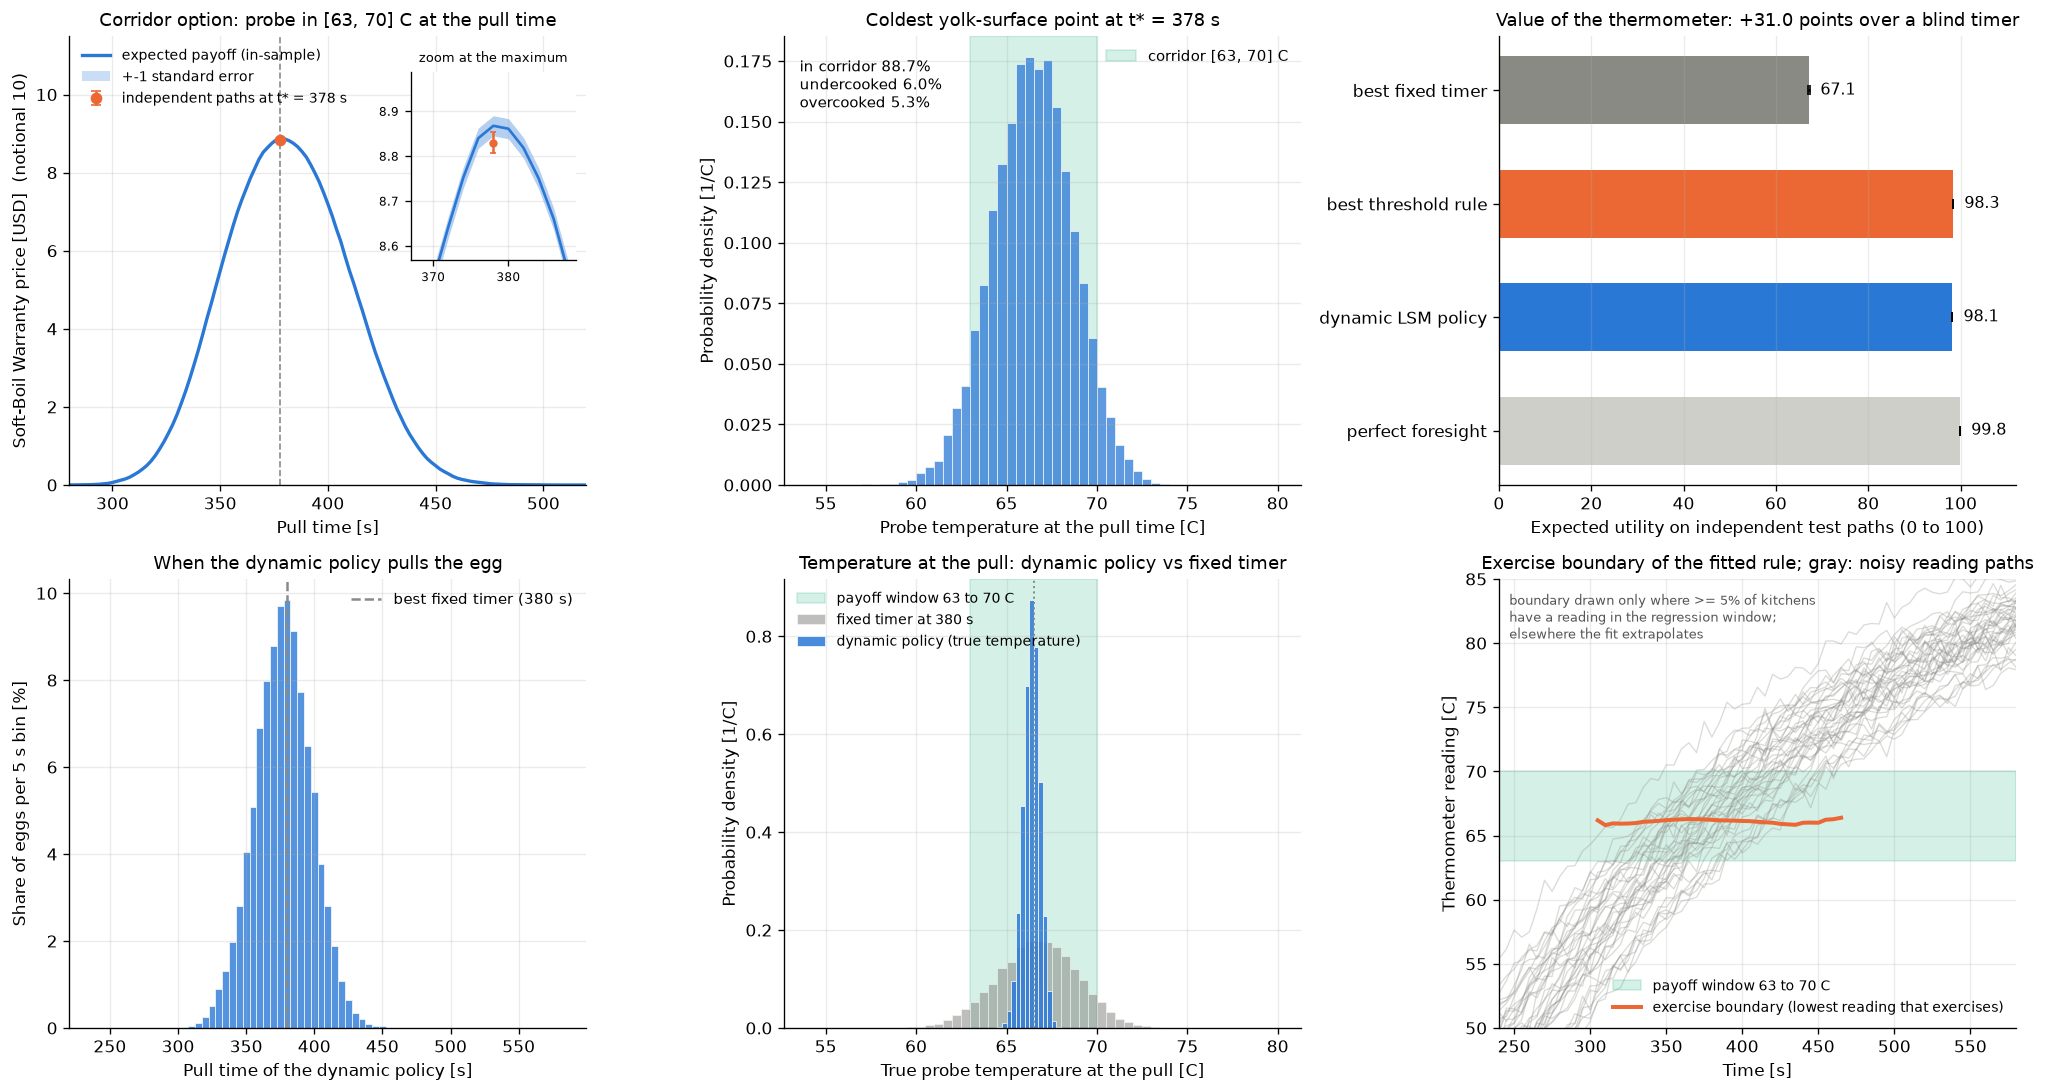

Exercise boundary drawn at 305 to 465 s; it ranges from 65.81 to 66.39 C there (median 66.12 C)


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9.2))

# (a) Corridor price curve with +-1 SE band, zoom inset, independent estimate at t_opt
ax = axes[0, 0]
tc, pr, se = cor["cook_times_s"], cor["prices"], cor["price_se"]
ax.plot(tc, pr, color=BLUE, lw=2.0, label="expected payoff (in-sample)")
ax.fill_between(tc, pr - se, pr + se, color=BLUE, alpha=0.25, lw=0, label="+-1 standard error")
ax.errorbar([t_opt], [price_oos], yerr=[price_oos_se], fmt="o", color=ORANGE, ms=6, capsize=3,
            label=f"independent paths at t* = {t_opt:.0f} s")
ax.axvline(t_opt, color=GRAY, ls="--", lw=1.0)
ax.set_xlim(280, 520)
ax.set_ylim(0, 11.5)
ax.set_xlabel("Pull time [s]")
ax.set_ylabel("Soft-Boil Warranty price [USD]  (notional 10)")
ax.set_title("Corridor option: probe in [63, 70] C at the pull time")
ax.legend(loc="upper left", fontsize=8.5)
axin = ax.inset_axes([0.66, 0.50, 0.32, 0.42])
zoom = (tc >= t_opt - 10) & (tc <= t_opt + 10)
axin.plot(tc[zoom], pr[zoom], color=BLUE, lw=1.6)
axin.fill_between(tc[zoom], (pr - se)[zoom], (pr + se)[zoom], color=BLUE, alpha=0.35, lw=0)
axin.set_ylim(price_max - 0.30, price_max + 0.12)
axin.errorbar([t_opt], [price_oos], yerr=[price_oos_se], fmt="o", color=ORANGE, ms=4, capsize=2)
axin.set_title("zoom at the maximum", fontsize=8)
axin.tick_params(labelsize=7)
axin.grid(alpha=0.25)

# (b) Probe-temperature distribution at t_opt against the corridor
ax = axes[0, 1]
T_at_opt = cor["T_samples_at_opt_C"]
ax.axvspan(63.0, 70.0, color=AQUA, alpha=0.18, label="corridor [63, 70] C")
ax.hist(T_at_opt, bins=np.arange(54.0, 80.01, 0.5), density=True, color=BLUE, alpha=0.75,
        edgecolor="white", linewidth=0.5)
ax.text(0.03, 0.95, f"in corridor {100 * p_in:.1f}%\nundercooked {100 * p_under:.1f}%\novercooked {100 * p_over:.1f}%",
        transform=ax.transAxes, va="top", fontsize=9)
ax.set_xlabel("Probe temperature at the pull time [C]")
ax.set_ylabel("Probability density [1/C]")
ax.set_title(f"Coldest yolk-surface point at t* = {t_opt:.0f} s")
ax.legend(loc="upper right")

# (c) Value comparison of the policies on the test paths
ax = axes[0, 2]
labels = ["best fixed timer", "best threshold rule", "dynamic LSM policy", "perfect foresight"]
vals = [fixed_val, thr["best_value"], amer["american_value"], foresight_val]
ses = [amer["best_fixed_value_se"], thr["best_value_se"], amer["american_value_se"],
       amer["perfect_foresight_value_se"]]
colors = [GRAY, ORANGE, BLUE, "#cfcfca"]
y_pos = np.arange(len(labels))[::-1]
ax.barh(y_pos, vals, xerr=ses, color=colors, height=0.6, error_kw={"capsize": 3})
for yy, v in zip(y_pos, vals):
    ax.text(v + 2.5, yy, f"{v:.1f}", va="center", fontsize=9.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.set_xlim(0, 112)
ax.set_xlabel("Expected utility on independent test paths (0 to 100)")
ax.set_title(f"Value of the thermometer: +{voi:.1f} points over a blind timer")
ax.grid(axis="y", visible=False)

# (d) Distribution of the dynamic policy's pull times
ax = axes[1, 0]
step = amer["decision_interval_s"]
edges = np.arange(tg[0] - step / 2, tg[-1] + step, step)
stop_t = amer["stopping_times_s"]
ax.hist(stop_t, bins=edges, weights=np.full(len(stop_t), 100.0 / len(stop_t)), color=BLUE, alpha=0.8,
        edgecolor="white", linewidth=0.5)
ax.axvline(amer["best_fixed_time_s"], color=GRAY, ls="--", lw=1.5,
           label=f"best fixed timer ({amer['best_fixed_time_s']:.0f} s)")
ax.set_xlabel("Pull time of the dynamic policy [s]")
ax.set_ylabel(f"Share of eggs per {step:.0f} s bin [%]")
ax.set_title("When the dynamic policy pulls the egg")
ax.legend(loc="upper right")

# (e) True probe temperature at the pull: dynamic policy vs fixed timer
ax = axes[1, 1]
T0_f, Tb_f, s_f = unc.sample(20000, 2024)
T_fixed = resp(np.array([amer["best_fixed_time_s"]]), T0_f, Tb_f, s_f) - KELVIN
ax.axvspan(63.0, 70.0, color=AQUA, alpha=0.18, label="payoff window 63 to 70 C")
ax.axvline(66.5, color=GRAY, ls=":", lw=1.2)
ax.hist(T_fixed, bins=np.arange(54.0, 80.01, 0.5), density=True, color=GRAY, alpha=0.55,
        edgecolor="white", linewidth=0.5, label=f"fixed timer at {amer['best_fixed_time_s']:.0f} s")
ax.hist(amer["stopping_temps_C"], bins=np.arange(54.0, 80.01, 0.25), density=True, color=BLUE, alpha=0.85,
        edgecolor="white", linewidth=0.5, label="dynamic policy (true temperature)")
ax.set_xlabel("True probe temperature at the pull [C]")
ax.set_ylabel("Probability density [1/C]")
ax.set_title("Temperature at the pull: dynamic policy vs fixed timer")
ax.legend(loc="upper left", fontsize=8.5)

# (f) Exercise boundary of the fitted rule against noisy reading paths
ax = axes[1, 2]
obs_paths = amer["T_obs_paths_C"]
for i in range(40):
    ax.plot(tg, obs_paths[i], color=GRAY, alpha=0.30, lw=0.8)
T0_w, Tb_w, s_w = unc.sample(20000, 777)
T_w = resp(tg[None, :], T0_w[:, None], Tb_w[:, None], s_w[:, None]) - KELVIN
obs_w = T_w + np.random.default_rng(778).normal(0.0, 0.5, T_w.shape)
share_in_window = np.mean(np.abs(obs_w - 66.5) <= 3.5 + 3 * 0.5, axis=0)
boundary = np.where(share_in_window >= 0.05, amer["exercise_boundary_C"], np.nan)
shown = tg[np.isfinite(boundary)]
ax.axhspan(63.0, 70.0, color=AQUA, alpha=0.18, label="payoff window 63 to 70 C")
ax.plot(tg, boundary, color=ORANGE, lw=2.4, label="exercise boundary (lowest reading that exercises)")
ax.set_ylim(50, 85)
ax.set_xlim(tg[0], tg[-1])
ax.set_xlabel("Time [s]")
ax.set_ylabel("Thermometer reading [C]")
ax.set_title("Exercise boundary of the fitted rule; gray: noisy reading paths")
ax.text(0.02, 0.97, "boundary drawn only where >= 5% of kitchens\nhave a reading in the regression window;\n"
        "elsewhere the fit extrapolates", transform=ax.transAxes, ha="left", va="top", fontsize=8,
        color="#555555")
ax.legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
fig.savefig("../figures/egg_options_pricing.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Exercise boundary drawn at {shown.min():.0f} to {shown.max():.0f} s; "
      f"it ranges from {np.nanmin(boundary):.2f} to {np.nanmax(boundary):.2f} C there "
      f"(median {np.nanmedian(boundary):.2f} C)")

## Summary

In [19]:
display(Markdown(f'''
| Quantitative finance concept | Egg-boiling counterpart | Key result |
|---|---|---|
| **Black-Scholes PDE and the 1D heat equation** | Log-price diffusion solved with `scikit-fem` P1 elements and Backward Euler | Max nodal error vs the exact call price: {max_err:.3g} USD on S in [{S_LO:.0f}, {S_HI:.0f}] ({N_NODES} nodes, {N_STEPS} steps). First order in time; unsafe at small sigma (the solver raises). |
| **Thermal underlying** | One FEM run of the default egg, similarity-scaled to other kitchens | White-set (63 C) at {t63_ref:.0f} s and the coldest yolk-surface point at 70 C at {t70_ref:.0f} s in the default kitchen. Scaled minus direct FEM crossing times within {max(abs(c['t_diff_s']).max() for _, c in sim_checks):.1f} s over five perturbed kitchens; the systematic part of that error raises the scaled corridor price by {big_sca['prices'][i_c] - big_tab['prices'][i_c]:.2f} USD and the scaled best fixed timer's value by {amer['best_fixed_value'] - amer_tab['best_fixed_value']:.1f} points (Section 5). |
| **European corridor digital option** | *Soft-Boil Warranty*: 10 USD if the coldest point of the yolk surface is in 63 to 70 C at the pull | Price on independent paths {fmt_pm(price_oos, price_oos_se)} USD at t* = {t_opt:.0f} s (in-sample max {fmt_pm(price_max, price_max_se)}); hit probability {100 * p_in:.1f}%. |
| **American option (Longstaff-Schwartz LSM)** | Pull the egg using a noisy in-egg thermometer (noise 0.5 C) | Dynamic {fmt_pm(amer['american_value'], amer['american_value_se'])} vs best fixed timer {fmt_pm(fixed_val, amer['best_fixed_value_se'])} (at {amer['best_fixed_time_s']:.0f} s): value of information {fmt_pm(voi, voi_se)} points. The one-parameter threshold rule is ahead of LSM: {fmt_pm(thr['best_value'], thr['best_value_se'])}. Perfect-foresight ceiling {fmt_pm(foresight_val, amer['perfect_foresight_value_se'])}. |
'''))


| Quantitative finance concept | Egg-boiling counterpart | Key result |
|---|---|---|
| **Black-Scholes PDE and the 1D heat equation** | Log-price diffusion solved with `scikit-fem` P1 elements and Backward Euler | Max nodal error vs the exact call price: 0.00354 USD on S in [50, 150] (401 nodes, 400 steps). First order in time; unsafe at small sigma (the solver raises). |
| **Thermal underlying** | One FEM run of the default egg, similarity-scaled to other kitchens | White-set (63 C) at 343 s and the coldest yolk-surface point at 70 C at 407 s in the default kitchen. Scaled minus direct FEM crossing times within 4.4 s over five perturbed kitchens; the systematic part of that error raises the scaled corridor price by 0.12 USD and the scaled best fixed timer's value by 1.3 points (Section 5). |
| **European corridor digital option** | *Soft-Boil Warranty*: 10 USD if the coldest point of the yolk surface is in 63 to 70 C at the pull | Price on independent paths 8.83 +- 0.02 USD at t* = 378 s (in-sample max 8.87 +- 0.02); hit probability 88.7%. |
| **American option (Longstaff-Schwartz LSM)** | Pull the egg using a noisy in-egg thermometer (noise 0.5 C) | Dynamic 98.14 +- 0.02 vs best fixed timer 67.13 +- 0.24 (at 380 s): value of information 31.01 +- 0.24 points. The one-parameter threshold rule is ahead of LSM: 98.32 +- 0.02. Perfect-foresight ceiling 99.803 +- 0.001. |


### What these numbers do and do not show

- The corridor "price" and the stopping "value" are expected culinary payoffs under an **assumed** kitchen distribution (Section 3), not market prices. The soft-boil window, the utility tent, the noise level and the kitchen spread are modeling choices; changing them changes the numbers, as the sensitivity tables show. The corridor price in particular depends strongly on the window width and on the size spread (Section 3 tables), and the kitchen model leaves out egg-to-egg variation of the yolk position.
- The thermal underlying is the FEM response of **one** egg geometry with a constant-temperature (Dirichlet) bath. Starting temperature and bath temperature enter through similarity scaling, which is approximate because the material properties depend on temperature; the check in Section 2 covers five perturbed kitchens of this egg only. The scaled response is not defined beyond the end of the stored FEM run (1200 s divided by $s^2$). Its errors are systematic: against a response tabulated from direct FEM runs (Section 5) the scaled one overstates the corridor price by about 0.12 USD (the Monte Carlo standard error is 0.02 USD) and the best fixed timer's value by about 1.3 points, so the value of information is understated by about 1.3 points (about 4%), while the values of the dynamic policies hardly change.
- The corridor probe is the coldest point of the yolk surface, one point of the egg. Inside the corridor 89% to 100% of the yolk-surface area and 24% to 41% of the yolk volume are already at or above $70^\circ\text{C}$ (Section 3), so the corridor describes a just-set white, not an unset yolk.
- Agreement of the 63 and 70 degree crossing times with cooking guides is a consistency check, not an independent validation of the FEM.
- The value of information is measured against a blind timer. The LSM rule is a feasible policy that uses only the current thermometer reading, so its value is a lower bound on what this thermometer allows, and it is not the best policy found here: with a fine (0.02 C) threshold grid chosen on the training paths, the one-parameter threshold rule is ahead of LSM by 0.19 points (standard error 0.002) in all 40 seeds, which is 0.6% of the value of information, and it is ahead at every noise level of the table above, including zero noise, where it comes within 0.002 points of the perfect-foresight ceiling. The 0.5 C threshold grid of an earlier version hid this gap, and other polynomial degrees do not close it. The value comes from having a thermometer, not from the dynamic programming.
- The exercise boundary is estimated from simulated paths and is only meaningful where many paths fall in the regression window (the figure shows it only there).